# CFP Ranker '26: Matchup Simulator
Predicts any matchup by **simulating the game play by play** many times, using the 2026 data in
`espn_cfb_2026.db` (built by `cfb2026.ipynb`), with last season's `espn_cfb_2025.db` as each team's starting point. Every snap is drawn from what the two teams have
actually done this season, so each simulated game produces a full box score: team stats and
individual passing, rushing, receiving, kicking and defensive lines.

## How it works

| Step | What it does | Data used |
| --- | --- | --- |
| 1. Classify plays | Tag every play as rush, dropback, punt, field goal, kickoff or penalty, and pull the rusher, passer and target out of the play text | `Plays`, `Games` |
| 2. Opponent-adjusted ratings | For yards per carry, completion %, sack %, INT %, yards per catch, big-play rates, fumbles and penalties, fit `league + offense + defense + home field`, starting from last season's ratings, so a team is judged against the defenses it actually faced (beating up on FCS teams counts for less). Home field is scaled to the real conference-game home margin | `Plays` (2026 and 2025), `Games` |
| 3. Tendencies | Pass rate by down, distance, score and clock (league model + a team offset), 4th-down go/kick/punt rates, field-goal make % by distance, punt and kickoff results, tempo | `Plays` |
| 4. Players | Who gets the carries, dropbacks and targets (recent games weigh more), each player's own yardage history, and who makes the tackles, sacks and interceptions | `Plays` text, `Player_Box_Scores` |
| 5. Simulate | Kickoff to final whistle with a game clock, 4th-down decisions, 2-point tries, onside kicks, kneel-downs and college overtime | everything above |

A simulated rush or catch is drawn from the ball carrier's real plays this season, then shifted by how
good the offense is against how good the opposing defense is. Rates such as completion % combine
the same way: league average + offense effect + defense effect.

**To predict a different game, change `AWAY_TEAM` / `HOME_TEAM` below and run all cells.**

## How accurate is it?
Backtested on the 405 FBS-vs-FBS games of weeks 4-10. Each week was predicted using only games played
before it (`AS_OF`), plus the full 2025 season, with 50 simulations per game. "Margin miss" is the average
gap between the predicted and actual final margin.

| Version | Picked the winner | Brier score (lower is better) | Margin miss |
| --- | --- | --- | --- |
| **This notebook** (2025 starting point, calibrated home field, big-play matchups) | **67.9%** | **0.205** | **12.8 pts** |
| Without big-play matchups | 67.4% | 0.213 | 13.0 pts |
| First version (2026 data only, ~1.5-pt home field) | 64.4% | 0.221 | 13.5 pts |
| Team with the better average scoring margin | 64.0% | n/a | n/a |
| Home team always | 56.0% | n/a | n/a |

**Optional features** (settings in section 1), each measured against the version without big-play matchups:

| Setting | Brier change | Kept? |
| --- | --- | --- |
| `EXPLOSIVE_MATCHUPS`: big-play rates (runs of 15+, catches of 20+) rated per offense and defense | -0.0075 (better) | on |
| `SCORING_FIXES`: real red-zone plays, breakaway TDs on long fields, gains by down and distance | -0.0040 | off: no gain on top of big plays |
| `AVAILABILITY`: regulars missing from recent games may sit out (ESPN publishes no college injury data) | -0.0016 | off: no gain on top of big plays |
| `GARBAGE_FILTER`: drop blowout plays from the ratings | +0.0051 (worse) | off |

These differences are small next to the noise in a 405-game test (about +/-0.005), so treat them as leanings,
not proof. Final margins are hard to predict: most of the ~13-point miss is game-to-game randomness that no
model can see (real margins have a standard deviation of about 19 points). With 100 simulations, a win %
also moves about +/-10 points between runs.

## 1. Setup

In [1]:
import copy
import math
import os
import random
import re
import sqlite3
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Matchup ---
AWAY_TEAM = "Tennessee"         # any part of a team name, e.g. "Tennessee", "Texas A&M", "Ohio State"
HOME_TEAM = "Texas A&M"
NEUTRAL_SITE = False             # True removes home-field advantage
N_SIMS = 500
SEED = random.randint(0, 1000000)                       # change for a different set of 100 games; None = random every run

# --- Data ---
YEAR = 2026
DB_FILE = f"espn_cfb_{YEAR}.db"
AS_OF = None                     # 'YYYY-MM-DD' to only use games before that date (None = every Final game)
RECENCY_DECAY = 0.80             # usage shares: last game weight 1, the one before 0.8, then 0.64, ...
STARTER_DECAY = 0.50             # starting QB odds: who started recent games, decaying much faster

# --- Model ---
RATING_DECAY = 1.00              # team ratings: a game n weeks older counts RATING_DECAY^n as much. 1.0 = all equal
                                 # (best in backtesting; 0.90 was slightly worse, see "How accurate is it?")
PRIOR_DB_FILE = f"espn_cfb_{YEAR - 1}.db"   # last season's data, each team's starting point (None to skip)
PRIOR_CARRYOVER = 0.50           # how much of last season's rating a team starts this season with
HOME_FIELD_POINTS = None         # home edge in points; None = measure it from conference games (both seasons)
# Optional model features. Each was backtested on its own (see "How accurate is it?"); only big plays clearly helped.
EXPLOSIVE_MATCHUPS = True        # big-play rates: this offense's vs this defense's, opponent-adjusted (best in backtest)
SCORING_FIXES = False            # red-zone plays from real red-zone snaps; breakaway plays can go the distance
AVAILABILITY = False             # regulars missing from recent box scores may sit out a simulated game
GARBAGE_FILTER = False           # leave blowout plays out of the team ratings (made predictions worse)

conn = sqlite3.connect(DB_FILE)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 2. Load and classify plays
Kneel-downs are dropped from the rushing data. Fumbles are assigned to the play they happened on
(a rush, a completion or a sack). Player names are pulled from the play text (`#18 D.Bishop rush ...`)
and reduced to a key like `d.bishop`, which also matches the full names in `Player_Box_Scores`.

In [2]:
RUSH_TYPES = {"Rush", "Rushing Touchdown"}
PASS_TYPES = {"Pass Reception", "Passing Touchdown", "Pass Incompletion", "Sack", "Interception",
              "Pass Interception Return", "Interception Return Touchdown"}
COMPLETE_TYPES = {"Pass Reception", "Passing Touchdown"}
INT_TYPES = {"Interception", "Pass Interception Return", "Interception Return Touchdown"}
FUMBLE_TYPES = {"Fumble Recovery (Own)", "Fumble Recovery (Opponent)", "Fumble", "Fumble Return Touchdown"}
FUMBLE_LOST_TYPES = {"Fumble Recovery (Opponent)", "Fumble Return Touchdown"}
PUNT_TYPES = {"Punt", "Punt Return", "Punt Return Touchdown", "Blocked Punt Touchdown"}
FG_TYPES = {"Field Goal Good", "Field Goal Missed", "Blocked Field Goal", "Blocked Field Goal Touchdown"}
KICKOFF_TYPES = {"Kickoff", "Kickoff Return (Offense)", "Kickoff Return Touchdown"}

_NAME = r"([A-Z][A-Za-z'\-]*\.\s?[A-Za-z][A-Za-z'\-\.]*(?: (?:Jr\.|Sr\.|(?:III|II|IV|V)\b))?)"
RUSHER_RE = re.compile(r"#\d+ " + _NAME + r" (?:rush|run)")
PASSER_RE = re.compile(r"#\d+ " + _NAME + r" (?:pass|sacked)")
TARGET_RE = re.compile(r"pass (?:complete|incomplete)[^#]*? to #\d+ " + _NAME)
# A few games use the older "Full Name pass complete to Full Name for 7 yds" style
FULL_PASS_RE = re.compile(r"^([A-Z][^()#\d]*?) pass (?:complete|incomplete) to ([A-Z][^()#\d]*?) for")
FULL_RUSH_RE = re.compile(r"^([A-Z][^()#\d]*?) (?:run|rush) for")
# Some touchdowns are stored as a scoring summary: "Deuce Alexander 62 Yd pass from Trinidad Chambliss (...)"
TD_PASS_RE = re.compile(r"^([A-Z][^()#\d]*?) \d+ Yd pass from ([A-Z][^()#\d]*?)(?: \(|$)")
TD_RUSH_RE = re.compile(r"^([A-Z][^()#\d]*?) \d+ Yd Run\b")
SUFFIXES = {"jr", "sr", "ii", "iii", "iv", "v"}


def name_key(name):
    """'D.Bishop', 'DeSean Bishop' -> 'd.bishop'; suffixes (Jr., II) are dropped."""
    if not isinstance(name, str) or not name.strip():
        return None
    tokens = [t for t in re.split(r"[\s.]+", name.strip()) if t]
    # Drop suffixes, but never the first token: an initial "V." is a first name, not "the fifth"
    tokens = tokens[:1] + [t for t in tokens[1:] if t.lower() not in SUFFIXES]
    if len(tokens) < 2:
        return None
    last = re.sub(r"[^a-z]", "", tokens[-1].lower())
    return f"{tokens[0][0].lower()}.{last}" if last else None


def _extract(texts, pattern, *fallbacks):
    """Name from `pattern`; if missing, try each (fallback_pattern, group) in turn. Returns name keys."""
    out = texts.str.extract(pattern, expand=False)
    for fb, group in fallbacks:
        out = out.fillna(texts.str.extract(fb, expand=True)[group - 1])
    return out.map(name_key)


def clock_seconds(clock):
    try:
        m, s = str(clock).split(":")
        return int(m) * 60 + int(s)
    except ValueError:
        return np.nan


def load_plays(conn, as_of=None):
    df = pd.read_sql("""
        SELECT p.game_id, p.drive_number, p.play_number_in_drive, p.drive_team_id, p.period, p.clock,
               p.play_type_text, p.text, p.start_down, p.start_distance, p.start_yards_to_endzone,
               p.start_team_id, p.stat_yardage, p.home_score, p.away_score,
               g.game_date, g.home_team_id, g.away_team_id, g.neutral_site
        FROM Plays p JOIN Games g ON g.game_id = p.game_id
        WHERE g.status = 'Final'""", conn)
    if as_of:
        df = df[df.game_date < as_of]
    df = df.sort_values(["game_id", "drive_number", "play_number_in_drive"]).reset_index(drop=True)

    t = df.play_type_text.fillna("")
    txt = df.text.fillna("")
    fumble = t.isin(FUMBLE_TYPES)
    kneel = txt.str.contains("kneel", case=False)
    is_rush = (t.isin(RUSH_TYPES) | (fumble & txt.str.contains(r" rush | run "))) & ~kneel
    is_pass = t.isin(PASS_TYPES) | (fumble & txt.str.contains(r"pass complete|pass incomplete|sacked"))
    df["kind"] = np.select(
        [is_rush, is_pass, kneel, t.isin(PUNT_TYPES), t.isin(FG_TYPES), t.isin(KICKOFF_TYPES), t.eq("Penalty")],
        ["rush", "pass", "kneel", "punt", "fg", "kickoff", "penalty"], default="other")

    df["off"] = df.start_team_id
    df["def"] = np.where(df.off == df.home_team_id, df.away_team_id, df.home_team_id)
    # +1 home offense, -1 away offense, 0 neutral site
    df["home_sign"] = np.where(df.neutral_site == 1, 0, np.where(df.off == df.home_team_id, 1, -1))
    conf = pd.read_sql("SELECT team_id, conference FROM Teams", conn).set_index("team_id").conference.replace("", np.nan)
    df["conf_game"] = (df.home_team_id.map(conf) == df.away_team_id.map(conf)).astype(int)
    df["ytez"] = df.start_yards_to_endzone
    df["yards"] = df.stat_yardage.fillna(0)
    df["sack"] = is_pass & (t.eq("Sack") | (fumble & txt.str.contains("sacked")))
    df["attempt"] = is_pass & ~df.sack
    df["complete"] = is_pass & (t.isin(COMPLETE_TYPES) | (fumble & txt.str.contains("pass complete")))
    df["interception"] = t.isin(INT_TYPES)
    df["fumble_lost"] = t.isin(FUMBLE_LOST_TYPES)
    df["off_td"] = t.isin({"Rushing Touchdown", "Passing Touchdown"})

    df["rusher"] = None
    df.loc[is_rush, "rusher"] = _extract(txt[is_rush], RUSHER_RE, (FULL_RUSH_RE, 1), (TD_RUSH_RE, 1))
    df["passer"] = None
    df.loc[is_pass, "passer"] = _extract(txt[is_pass], PASSER_RE, (FULL_PASS_RE, 1), (TD_PASS_RE, 2))
    df["target"] = None
    att = df.attempt
    df.loc[att, "target"] = _extract(txt[att], TARGET_RE, (FULL_PASS_RE, 2), (TD_PASS_RE, 1))

    # Score from the offense's point of view *before* the snap (score columns are after the play)
    prev_home = df.groupby("game_id").home_score.shift(1).fillna(0)
    prev_away = df.groupby("game_id").away_score.shift(1).fillna(0)
    off_home = df.off == df.home_team_id
    df["diff"] = np.where(off_home, prev_home - prev_away, prev_away - prev_home)
    # Garbage time (Bill Connelly's definition): lead of more than 43 / 37 / 27 / 21 points in Q1 / Q2 / Q3 / Q4
    lead = df["diff"].abs()
    df["garbage"] = (((df.period == 1) & (lead > 43)) | ((df.period == 2) & (lead > 37))
                     | ((df.period == 3) & (lead > 27)) | ((df.period >= 4) & (lead > 21)))
    df["clock_s"] = df.clock.map(clock_seconds)
    snap = txt.str.extract(r"^\((\d+):(\d+)\)")
    df["snap_s"] = snap[0].astype(float) * 60 + snap[1].astype(float)
    df["secs_left"] = np.where(df.period <= 4, (4 - df.period.clip(upper=4)) * 900 + df.clock_s, 0)

    # Where the next drive started (yards to the end zone for the team that got the ball), used for
    # kickoffs, punts and turnovers. Taken from the next rush/pass/penalty snap by the other team.
    scrimmage = df.kind.isin(["rush", "pass", "penalty", "kneel"])
    nxt = pd.Series(np.where(scrimmage, df.index, np.nan), index=df.index)
    nxt = nxt.groupby(df.game_id).shift(-1)
    nxt = nxt.groupby(df.game_id).bfill()
    idx = nxt.dropna().astype(int)
    df["next_off"] = None
    df["next_ytez"] = np.nan
    df.loc[idx.index, "next_off"] = df.loc[idx.values, "off"].values
    df.loc[idx.index, "next_ytez"] = df.loc[idx.values, "ytez"].values
    df["next_period"] = np.nan
    df.loc[idx.index, "next_period"] = df.loc[idx.values, "period"].values
    df["poss_flip_ok"] = (df.next_off == df["def"]) & (
        (df.next_period == df.period) | ((df.period == 1) & (df.next_period == 2)) | ((df.period == 3) & (df.next_period == 4)))
    return df


plays = load_plays(conn, AS_OF)
teams = pd.read_sql("SELECT team_id, display_name, short_name, conference FROM Teams", conn).set_index("team_id")
print(f"{len(plays):,} plays from {plays.game_id.nunique()} Final games")
print(plays.kind.value_counts().to_string())

parsed = pd.Series({
    "rusher found on rushes": plays.loc[plays.kind == "rush", "rusher"].notna().mean(),
    "passer found on dropbacks": plays.loc[plays.kind == "pass", "passer"].notna().mean(),
    "target found on attempts": plays.loc[plays.attempt, "target"].notna().mean(),
})
print("\n" + parsed.map("{:.1%}".format).to_string())

123,075 plays from 691 Final games
kind
rush       45781
pass       44175
other      10371
kickoff     7402
penalty     6616
punt        5793
fg          2126
kneel        811

rusher found on rushes       98.3%
passer found on dropbacks    98.5%
target found on attempts     95.7%


## 3. Opponent-adjusted team ratings
Each per-play outcome is modelled as `league average + offense effect + defense effect + home field`.
The effects are solved together (alternating least squares), so a team is judged against the
opponents it actually faced. Three things keep the ratings honest:

- **Last season as the starting point.** Each team starts from `PRIOR_CARRYOVER` (50%) of its 2025 rating
  (teams turn over a lot, so only part of it carries). 2026 plays then pull it toward this season:
  after `k` plays of evidence the two count equally, and by midseason 2026 dominates.
- **Optional recency weighting.** Each play can be weighted `RATING_DECAY ^ weeks_ago`, so a team is rated
  more on how it plays now than in September. It is off by default (`1.0`): at 0.90 the backtest got slightly
  worse, because down-weighting old games throws away too much data. (Who gets the ball is always
  recency-weighted; see section 5.)
- **Home field from conference games only.** Home teams are usually the stronger side in non-conference
  "buy" games, which would inflate the home effect.

Yardage is capped (winsorized) only for fitting the averages; simulated plays still use the real values,
long runs included.

In [3]:
def add_recency_weights(df, as_of=None, decay=1.0):
    """Weight each play by decay ** (weeks before the reference date), normalized to average 1."""
    dates = pd.to_datetime(df.game_date, utc=True)
    ref = pd.Timestamp(as_of, tz="UTC") if as_of else dates.max()
    w = decay ** ((ref - dates).dt.total_seconds().clip(lower=0) / (7 * 86400))
    return df.assign(w=w / w.mean())


OPEN_FIELD = 25                      # yardage pools use snaps starting more than this many yards from the end zone
EXPLOSIVE = {"rush": 15, "catch": 20}  # a big play: a run of 15+ or a catch of 20+ yards


def rating_frames(p):
    """Per-play tables the ratings are fit on (also used for yardage pools and penalties)."""
    if GARBAGE_FILTER:
        p = p[~p.garbage]
    rush = p[p.kind == "rush"].assign(y=lambda x: x.yards.clip(-10, 40))
    drop = p[p.kind == "pass"].assign(sack_i=lambda x: x.sack.astype(float))
    atts = drop[drop.attempt].assign(comp_i=lambda x: x.complete.astype(float),
                                     int_i=lambda x: x.interception.astype(float))
    comps = atts[atts.complete].assign(y=lambda x: x.yards.clip(-5, 60))
    touches = pd.concat([rush, comps]).assign(fum_i=lambda x: x.fumble_lost.astype(float))
    # Penalties: committed by the offense (yards lost) or the defense (yards gained), per snap
    pens = p[p.kind.isin(["rush", "pass", "penalty"])].copy()
    pens["gain"] = pens.ytez - pens.groupby("game_id").ytez.shift(-1)
    is_pen = pens.kind.eq("penalty") & pens.gain.notna()
    pens["off_pen"] = (is_pen & (pens.gain < 0)).astype(float)
    pens["def_pen"] = (is_pen & (pens.gain > 0)).astype(float)
    # Big-play rates, on open-field snaps (near the goal line a 20-yard gain isn't possible)
    rush_open = rush[rush.ytez > OPEN_FIELD].assign(x_i=lambda x: (x.yards >= EXPLOSIVE["rush"]).astype(float))
    comps_open = comps[comps.ytez > OPEN_FIELD].assign(x_i=lambda x: (x.yards >= EXPLOSIVE["catch"]).astype(float))
    return {"rush": rush, "drop": drop, "atts": atts, "comps": comps, "touches": touches, "pens": pens,
            "rush_open": rush_open, "comps_open": comps_open}


# rating name: (table, column, shrinkage k in plays)
RATING_SPECS = {
    "rush_ypc": ("rush", "y", 150), "comp_pct": ("atts", "comp_i", 120), "sack_pct": ("drop", "sack_i", 200),
    "int_pct": ("atts", "int_i", 400), "yds_per_catch": ("comps", "y", 120), "fumble_pct": ("touches", "fum_i", 800),
    "off_pen": ("pens", "off_pen", 400), "def_pen": ("pens", "def_pen", 400),
    "rush_explosive": ("rush_open", "x_i", 250), "catch_explosive": ("comps_open", "x_i", 200),
}


def fit_effects(df, value, k_off, k_def, prior=None, iters=30):
    """Return (league_mean, offense_effects, defense_effects, home_effect) for a per-play value.

    With `prior` (last season's fit), each team is shrunk toward PRIOR_CARRYOVER x its prior effect
    instead of toward zero. Plays are weighted by the `w` column (recency).
    """
    v = df[value].astype(float)
    w = df["w"] if "w" in df else pd.Series(1.0, index=df.index)
    league = float((v * w).sum() / w.sum())
    r = v - league
    off, dfn = df["off"], df["def"]
    sign = (df["home_sign"] * df["conf_game"]).astype(float)
    n_off, n_def = w.groupby(off).sum(), w.groupby(dfn).sum()
    if prior is not None:
        o0 = (PRIOR_CARRYOVER * prior[1]).reindex(n_off.index).fillna(0.0)
        d0 = (PRIOR_CARRYOVER * prior[2]).reindex(n_def.index).fillna(0.0)
    else:
        o0, d0 = pd.Series(0.0, index=n_off.index), pd.Series(0.0, index=n_def.index)
    o, d, h = o0.copy(), d0.copy(), 0.0
    for _ in range(iters):
        res = r - dfn.map(d) - h * sign
        o = ((res * w).groupby(off).sum() + k_off * o0) / (n_off + k_off)
        res = r - off.map(o) - h * sign
        d = ((res * w).groupby(dfn).sum() + k_def * d0) / (n_def + k_def)
        res = r - off.map(o) - dfn.map(d)
        h = float((res * sign * w).sum() / max((sign ** 2 * w).sum(), 1))
    return league, o, d, h


def fit_all(frames, prior=None):
    return {name: fit_effects(frames[tbl], col, k, k, prior=None if prior is None else prior[name])
            for name, (tbl, col, k) in RATING_SPECS.items()}


# Last season: fit with every game weighted equally
PRIOR_RATINGS, prior_plays = None, None
if PRIOR_DB_FILE and os.path.exists(PRIOR_DB_FILE):
    prior_conn = sqlite3.connect(PRIOR_DB_FILE)
    prior_plays = load_plays(prior_conn)
    PRIOR_FRAMES = rating_frames(prior_plays)
    PRIOR_RATINGS = fit_all(PRIOR_FRAMES)
    print(f"Prior season: {len(prior_plays):,} plays from {prior_plays.game_id.nunique()} games in {PRIOR_DB_FILE}")
else:
    print("No prior-season database found; ratings start from league average")

plays = add_recency_weights(plays, AS_OF, RATING_DECAY)
FRAMES = rating_frames(plays)
rush, drop, atts, comps, pens = (FRAMES[k] for k in ("rush", "drop", "atts", "comps", "pens"))
RATINGS = fit_all(FRAMES, PRIOR_RATINGS)


def rating_table(team_ids):
    rows = []
    for tid in team_ids:
        row = {"team": teams.display_name.get(tid, tid)}
        for name, (lg, o, d, h) in RATINGS.items():
            row[f"off_{name}"] = lg + o.get(tid, 0.0)
            row[f"def_{name}"] = lg + d.get(tid, 0.0)
        rows.append(row)
    return pd.DataFrame(rows).set_index("team").T


print("League averages:", {k: round(v, 3) for k, (v, *_) in RATINGS.items()})

Prior season: 170,611 plays from 956 games in espn_cfb_2025.db
League averages: {'rush_ypc': 4.939, 'comp_pct': 0.62, 'sack_pct': 0.062, 'int_pct': 0.024, 'yds_per_catch': 11.666, 'fumble_pct': 0.006, 'off_pen': 0.043, 'def_pen': 0.024, 'rush_explosive': 0.073, 'catch_explosive': 0.176}


### Home-field advantage
The per-play home effects above are small and noisy (about +0.1 yards per carry), and on their own they
added only ~1.5 points per game in simulation. Real home teams win conference games by more than that,
partly through things the per-play model doesn't see (crowd noise, travel, officiating). So the model
keeps the *shape* of the per-play effects (which stats home teams do better at, pooled over both seasons),
and scales them so a simulated home game is worth `HOME_FIELD_POINTS`: by default the average home margin
in conference games, where schedules are balanced.

`SIM_POINTS_PER_UNIT` is how many points the unscaled effects add in simulation, measured offline by
simulating 60 real conference matchups 200 times each at home and at a neutral site.

In [4]:
SIM_POINTS_PER_UNIT = 2.075   # measured: +4.15 +/- 0.18 pts at 2x scale over 12,000 home/neutral game pairs


def conference_home_margins(c, as_of=None):
    g = pd.read_sql("""
        SELECT g.game_date, g.home_score - g.away_score AS margin
        FROM Games g JOIN Teams h ON h.team_id = g.home_team_id JOIN Teams a ON a.team_id = g.away_team_id
        WHERE g.status = 'Final' AND COALESCE(g.neutral_site, 0) = 0
          AND h.conference = a.conference AND COALESCE(h.conference, '') != ''""", c)
    return g[g.game_date < as_of].margin if as_of else g.margin


margins = conference_home_margins(conn, AS_OF)
if PRIOR_RATINGS is not None:
    margins = pd.concat([margins, conference_home_margins(prior_conn)])
MEASURED_HOME_POINTS = margins.mean()
HOME_POINTS = MEASURED_HOME_POINTS if HOME_FIELD_POINTS is None else HOME_FIELD_POINTS


def pooled_home_effect(name):
    """Per-play home effect pooled over both seasons, weighted by conference snaps."""
    tbl = RATING_SPECS[name][0]
    fits = [(RATINGS[name][3], int((FRAMES[tbl].conf_game == 1).sum()))]
    if PRIOR_RATINGS is not None:
        fits.append((PRIOR_RATINGS[name][3], int((PRIOR_FRAMES[tbl].conf_game == 1).sum())))
    return sum(h * n for h, n in fits) / max(sum(n for _, n in fits), 1)


HOME_EFFECT = {name: pooled_home_effect(name) for name in RATING_SPECS}
HOME_FIELD_SCALE = HOME_POINTS / SIM_POINTS_PER_UNIT
print(f"Conference-game home margin: {MEASURED_HOME_POINTS:+.2f} pts over {len(margins)} games "
      f"(se {margins.std() / len(margins) ** 0.5:.2f}); using {HOME_POINTS:+.2f}")
print(f"Per-play home effects scaled x{HOME_FIELD_SCALE:.2f}:",
      {k: round(float(v) * HOME_FIELD_SCALE, 4) for k, v in HOME_EFFECT.items()})

Conference-game home margin: +2.53 pts over 937 games (se 0.61); using +2.53
Per-play home effects scaled x1.22: {'rush_ypc': np.float64(0.09), 'comp_pct': np.float64(0.0047), 'sack_pct': np.float64(-0.0036), 'int_pct': np.float64(-0.0013), 'yds_per_catch': np.float64(0.102), 'fumble_pct': np.float64(0.0002), 'off_pen': np.float64(-0.0039), 'def_pen': np.float64(0.0006), 'rush_explosive': np.float64(0.0045), 'catch_explosive': np.float64(0.0044)}


## 4. League tendencies
These are fit from every team, then nudged per team where the data supports it:

- **Pass rate**: a logistic model on down, distance, score margin (more passing when behind, scaled
  by how late it is) and the final two minutes of a half, plus a shrunk per-team offset.
- **4th down**: how often teams go for it, kick or punt for each field position and distance.
- **Field goals**: logistic make % by distance, plus a shrunk per-kicker offset.
- **Kickoffs, punts, turnovers**: where the next drive actually started.
- **Tempo**: seconds from snap to snap by play result, plus a per-team pace factor.

In [5]:
def dist_bucket(dist):
    return 0 if dist <= 1 else 1 if dist <= 3 else 2 if dist <= 6 else 3 if dist <= 10 else 4


def fit_logistic(X, y, l2=1.0, iters=25):
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        grad = X.T @ (y - p) - l2 * w
        hess = (X * (p * (1 - p))[:, None]).T @ X + l2 * np.eye(X.shape[1])
        w += np.linalg.solve(hess, grad)
    return w


def pass_features(down, dist, diff, secs_left, two_min):
    """Feature vector: one-hot of (down, distance bucket), then game-script terms."""
    cell = np.zeros(20)
    cell[(min(max(down, 1), 4) - 1) * 5 + dist_bucket(dist)] = 1
    late = 1 - secs_left / 3600
    d = max(min(diff, 28), -28)
    return np.concatenate([cell, [d / 7, d / 7 * late, two_min, two_min * (diff <= 0)]])


sit = plays[plays.kind.isin(["rush", "pass"]) & plays.start_down.between(1, 4) & (plays.period <= 4)].copy()
sit["two_min"] = ((sit.clock_s <= 120) & sit.period.isin([2, 4])).astype(float)
X_pass = np.array([pass_features(dn, ds, df_, sl, tm) for dn, ds, df_, sl, tm in
                   zip(sit.start_down, sit.start_distance, sit["diff"], sit.secs_left, sit.two_min)])
y_pass = (sit.kind == "pass").values.astype(float)
W_PASS = fit_logistic(X_pass, y_pass)
sit["p_hat"] = 1 / (1 + np.exp(-X_pass @ W_PASS))
g = (y_pass - sit.p_hat).groupby(sit.off)
PASS_OFFSET = g.sum() / ((sit.p_hat * (1 - sit.p_hat)).groupby(sit.off).sum() + 60)  # one Newton step, shrunk

# 4th-down decisions by field position and distance
fourth = plays[(plays.start_down == 4) & plays.kind.isin(["rush", "pass", "punt", "fg"]) & (plays.period <= 4)].copy()
fourth["choice"] = fourth.kind.replace({"rush": "go", "pass": "go"})
fourth["ybin"] = (fourth.ytez.clip(1, 99) // 5).astype(int)
fourth["dbin"] = fourth.start_distance.map(dist_bucket)
FOURTH = (fourth.groupby(["ybin", "dbin"]).choice.value_counts().unstack(fill_value=0)
          .reindex(columns=["go", "fg", "punt"], fill_value=0))

# Field goals: P(make) by kick distance (yards to end zone + 17)
fgs = plays[plays.kind == "fg"].copy()
fgs["dist"] = fgs.ytez + 17
fgs["made"] = fgs.play_type_text.eq("Field Goal Good").astype(float)
W_FG = fit_logistic(np.c_[np.ones(len(fgs)), fgs.dist / 10], fgs.made.values, l2=0.01)
fgs["p_hat"] = 1 / (1 + np.exp(-(W_FG[0] + W_FG[1] * fgs.dist / 10)))
g = (fgs.made - fgs.p_hat).groupby(fgs.off)
FG_OFFSET = g.sum() / ((fgs.p_hat * (1 - fgs.p_hat)).groupby(fgs.off).sum() + 8)

xp = pd.read_sql("""SELECT display_value FROM Player_Box_Scores
                    WHERE stat_name = 'extraPointsMade/extraPointAttempts'""", conn).display_value.str.split("/", expand=True)
XP_RATE = xp[0].astype(float).sum() / max(xp[1].astype(float).sum(), 1)
TWO_PT_RATE = 0.45   # too few 2-pt tries in the data to fit; this is the long-run FBS rate

# Field position after change of possession (yards to end zone for the team receiving the ball)
flip = plays[plays.poss_flip_ok & plays.next_ytez.between(1, 99)]
KICKOFF_POOL = flip.loc[flip.kind == "kickoff", "next_ytez"].values
KR_TD_RATE = plays.play_type_text.eq("Kickoff Return Touchdown").sum() / max((plays.kind == "kickoff").sum(), 1)
punts = flip[flip.kind == "punt"].copy()
punts["net"] = punts.ytez - (100 - punts.next_ytez)
punts["sbin"] = (punts.ytez.clip(30, 99) // 10).astype(int)
PUNT_POOLS = {b: g_.next_ytez.values for b, g_ in punts.groupby("sbin")}
punts["resid"] = punts.net - punts.groupby("sbin").net.transform("mean")
g = punts.resid.groupby(punts.off)
PUNT_SHIFT = g.sum() / (g.count() + 25)
PR_TD_RATE = plays.play_type_text.isin({"Punt Return Touchdown", "Blocked Punt Touchdown"}).sum() / max((plays.kind == "punt").sum(), 1)

turnovers = flip[flip.interception | flip.fumble_lost]
# Change relative to simply flipping the line of scrimmage (negative = new offense got a short field)
TURNOVER_DELTA = {
    "int": (turnovers[turnovers.interception].next_ytez - (100 - turnovers[turnovers.interception].ytez)).values,
    "fumble": (turnovers[turnovers.fumble_lost].next_ytez - (100 - turnovers[turnovers.fumble_lost].ytez)).values,
}
PICK_SIX_RATE = plays.play_type_text.eq("Interception Return Touchdown").sum() / max(plays.interception.sum(), 1)
FUMBLE_TD_RATE = plays.play_type_text.eq("Fumble Return Touchdown").sum() / max(plays.fumble_lost.sum(), 1)
SACK_POOL = drop.loc[drop.sack, "yards"].clip(-25, 0).values

# Penalty yardage (rates per snap are rated per team in section 3)
OFF_PEN_YDS = (-pens.loc[pens.off_pen == 1, "gain"]).clip(1, 20).round().values
DEF_PEN_YDS = pens.loc[pens.def_pen == 1, "gain"].clip(1, 40).round().values

# Tempo: seconds from this snap to the next snap in the same drive and quarter
tempo = plays[plays.kind.isin(["rush", "pass"])].copy()
nxt_snap = plays.groupby(["game_id", "drive_number", "period"]).snap_s.shift(-1).reindex(tempo.index)
tempo["secs"] = tempo.snap_s - nxt_snap
tempo = tempo[tempo.secs.between(3, 60)]
tempo["result"] = np.where(tempo.kind == "rush", "rush", np.where(tempo.complete, "complete",
                           np.where(tempo.sack, "sack", "incomplete")))
# Scaled so simulated games average the same number of snaps as real 2026 FBS games (~65 per team);
# raw snap-to-snap times alone run the clock a bit fast because they miss quick snaps around penalties
# and timeouts.
TEMPO_SCALE = 0.80
TEMPO = (tempo.groupby("result").secs.mean() * TEMPO_SCALE).to_dict()
normal = tempo[tempo.result.isin(["rush", "complete"]) & (tempo.clock_s > 300)]
ratio = normal.secs / normal.result.map(TEMPO)
g = (ratio - 1).groupby(normal.off)
PACE = 1 + g.sum() / (g.count() + 150)

print(f"Pass-rate model fit on {len(sit):,} snaps; league pass rate {y_pass.mean():.1%}")
print(f"FG make %: 30 yds {1/(1+np.exp(-(W_FG[0]+W_FG[1]*3))):.0%}, 40 yds {1/(1+np.exp(-(W_FG[0]+W_FG[1]*4))):.0%}, "
      f"50 yds {1/(1+np.exp(-(W_FG[0]+W_FG[1]*5))):.0%}; XP {XP_RATE:.1%}")
print(f"Kickoff return TD {KR_TD_RATE:.2%}, punt return TD {PR_TD_RATE:.2%}, pick-six {PICK_SIX_RATE:.1%} of INTs, "
      f"fumble return TD {FUMBLE_TD_RATE:.1%} of lost fumbles")
print("Average seconds snap-to-snap:", {k: round(v) for k, v in TEMPO.items()})

Pass-rate model fit on 89,681 snaps; league pass rate 49.1%
FG make %: 30 yds 88%, 40 yds 74%, 50 yds 52%; XP 97.9%
Kickoff return TD 0.39%, punt return TD 0.79%, pick-six 10.2% of INTs, fumble return TD 6.5% of lost fumbles
Average seconds snap-to-snap: {'complete': 25, 'incomplete': 5, 'rush': 27, 'sack': 29}


## 5. Players
Usage shares (carries, dropbacks, targets) come from the play text and are **recency-weighted**, so a
QB change or an injury shows up within a couple of games. Each ball carrier's yardage is drawn from
his own plays, blended with the team's plays when he has only a handful. Names come from
`Player_Box_Scores`, as do tackles, sacks and interceptions for crediting the defense.

In [6]:
player_box = pd.read_sql("""
    SELECT b.game_id, b.team_id, b.player_id, b.player_name, b.stat_category, b.stat_name, b.stat_value,
           b.display_value, g.game_date
    FROM Player_Box_Scores b JOIN Games g ON g.game_id = b.game_id
    WHERE g.status = 'Final'""", conn)
if AS_OF:
    player_box = player_box[player_box.game_date < AS_OF]
player_box = player_box[player_box.player_name.str.strip().ne("Team")]
player_box["key"] = player_box.player_name.map(name_key)


class YardPool:
    """Real gains (and whether each one scored) for one player or team, split into big plays and the rest."""

    def __init__(self, yards, td, threshold):
        yards, td = np.asarray(yards, dtype=float), np.asarray(td, dtype=bool)
        big = yards >= threshold
        self.n, self.n_big = len(yards), int(big.sum())
        self.all, self.big, self.normal = (yards, td), (yards[big], td[big]), (yards[~big], td[~big])
        order = np.argsort(yards, kind="stable")
        self.sorted = (yards[order], td[order])   # for continuing a breakaway play

    def clip_mean(self, part, clip):
        ys = part[0] if len(part[0]) else self.all[0]
        return float(np.clip(ys, *clip).mean()) if len(ys) else 0.0


# Red zone: league plays by distance to the goal line. Gains there are squeezed by the end zone,
# so open-field plays don't transfer.
RZ_BINS = [0, 2, 5, 10, 15, 20]
rz_bucket = lambda ytez: int(np.searchsorted(RZ_BINS, ytez, side="left")) - 1
RZ_POOLS = {}
for kind, df_ in (("rush", rush), ("catch", comps)):
    rz = df_[df_.ytez.between(1, 20)]
    RZ_POOLS[kind] = {b: (g_.yards.values.astype(float), g_.off_td.values.astype(bool))
                      for b, g_ in rz.groupby(rz.ytez.map(rz_bucket))}
rz_atts = atts[atts.ytez.between(1, 20)]
COMP_RZ_DELTA = (rz_atts.groupby(rz_atts.ytez.map(rz_bucket)).complete.mean() - atts.complete.mean()).to_dict()

# Situation: real gains depend on down and distance (defenses concede more underneath on 3rd-and-long).
# League average open-field gain by (down group, distance bucket) minus the overall average.
def _situation_delta(df_, clip):
    o = df_[df_.ytez > OPEN_FIELD]
    grp = [o.start_down.clip(1, 3), o.start_distance.map(dist_bucket)]
    return (o.yards.clip(*clip).groupby(grp).mean() - o.yards.clip(*clip).mean()).to_dict()


SITUATION_DELTA = {"rush": _situation_delta(rush, (-10, 40)), "catch": _situation_delta(comps, (-5, 60))}


# Availability: a regular (played in 3+ games and at least half of his team's games) who is missing from
# the most recent box scores and play-by-play is probably hurt. How often such players are back the next
# game is measured from both seasons.
def appearances(box_df, plays_df):
    """(team_id, game_id) -> name keys that appear in the box score or as a ball carrier/passer/target."""
    app = defaultdict(set)
    for t, g, k in box_df[["team_id", "game_id", "key"]].dropna().itertuples(index=False):
        app[(t, g)].add(k)
    for col in ("rusher", "passer", "target"):
        for t, g, k in plays_df.loc[plays_df[col].notna(), ["off", "game_id", col]].itertuples(index=False):
            app[(t, g)].add(k)
    return app


def team_games(plays_df):
    order = defaultdict(list)
    games = plays_df[["game_id", "game_date", "home_team_id", "away_team_id"]].drop_duplicates("game_id")
    for gid, _, h, a in games.sort_values("game_date").itertuples(index=False):
        order[h].append(gid)
        order[a].append(gid)
    return order


def missed_streak(seq):
    """Games missed in a row at the end of `seq`, or None if the player isn't a regular."""
    played = sum(seq)
    if played < 3 or played / len(seq) < 0.5:
        return None
    k = 0
    while k < len(seq) and not seq[-1 - k]:
        k += 1
    return k


def return_rates(app, order):
    hits, counts = Counter(), Counter()
    for team, games in order.items():
        players = set().union(*(app.get((team, g), set()) for g in games))
        for p in players:
            seq = [p in app.get((team, g), ()) for g in games]
            for t in range(3, len(seq)):
                k = missed_streak(seq[:t])
                if k is not None:
                    counts[min(k, 3)] += 1
                    hits[min(k, 3)] += seq[t]
    return {k: hits[k] / counts[k] for k in sorted(counts)}


APPEAR = appearances(player_box, plays)
TEAM_GAMES = team_games(plays)
history = [(APPEAR, TEAM_GAMES)]
if prior_plays is not None:
    prior_box = pd.read_sql("SELECT DISTINCT game_id, team_id, player_name FROM Player_Box_Scores", prior_conn)
    prior_box = prior_box.assign(key=prior_box.player_name.map(name_key))
    history.append((appearances(prior_box, prior_plays), team_games(prior_plays)))
RETURN_RATE = Counter()
_n = Counter()
for app_, order_ in history:
    for k, v in return_rates(app_, order_).items():
        RETURN_RATE[k] += v; _n[k] += 1
RETURN_RATE = {k: RETURN_RATE[k] / _n[k] for k in RETURN_RATE}
print("Chance a regular plays, by games just missed in a row:",
      {f"{k}{'+' if k == 3 else ''} missed": f"{v:.0%}" for k, v in RETURN_RATE.items()})


def availability(team_id):
    """name key -> chance he plays, for regulars who missed the team's most recent game(s)."""
    games = TEAM_GAMES.get(team_id, [])
    players = set().union(*(APPEAR.get((team_id, g), set()) for g in games)) if games else set()
    out = {}
    for p in players:
        k = missed_streak([p in APPEAR.get((team_id, g), ()) for g in games])
        if k:
            out[p] = RETURN_RATE.get(min(k, 3), 1.0)
    return out


def game_weights(team_id):
    """game_id -> recency weight for this team's games (most recent = 1)."""
    games = (plays.loc[(plays.off == team_id) | (plays["def"] == team_id), ["game_id", "game_date"]]
             .drop_duplicates().sort_values("game_date", ascending=False))
    return {gid: RECENCY_DECAY ** i for i, gid in enumerate(games.game_id)}


def weighted_shares(rows, key_col, weights, min_share=0.005):
    w = rows.game_id.map(weights).fillna(0)
    s = w.groupby(rows[key_col]).sum()
    s = s[s > 0]
    s = s / s.sum()
    return s[s >= min_share].sort_values(ascending=False)


def display_names(team_id):
    """name key -> full display name, using whoever has the most box-score rows with that key."""
    b = player_box[player_box.team_id == team_id]
    return b.groupby("key").player_name.agg(lambda x: x.value_counts().index[0]).to_dict()


def box_stat_shares(team_id, category, stat, weights, prior=None):
    b = player_box[(player_box.team_id == team_id) & (player_box.stat_category == category)
                   & (player_box.stat_name == stat)]
    w = b.game_id.map(weights).fillna(0) * b.stat_value.fillna(0)
    s = w.groupby(b.player_name).sum()
    if prior is not None:
        s = s.add(prior, fill_value=0)
    s = s[s > 0]
    return (s / s.sum()).sort_values(ascending=False) if len(s) else s


def top_box_player(team_id, category, stat, weights):
    b = player_box[(player_box.team_id == team_id) & (player_box.stat_category == category)]
    if stat.endswith("Attempts"):
        vals = b[b.stat_name == stat].display_value.str.split("/").str[-1].astype(float)
        b = b[b.stat_name == stat].assign(stat_value=vals.values)
    else:
        b = b[b.stat_name == stat]
    if b.empty:
        return None
    w = b.game_id.map(weights).fillna(0) * b.stat_value.fillna(0)
    s = w.groupby(b.player_name).sum()
    return s.idxmax() if s.max() > 0 else None


class Roster:
    """Who touches the ball for one team, and each player's own play history."""

    def __init__(self, team_id):
        self.team_id = team_id
        self.name = teams.display_name.get(team_id, team_id)
        self.short = teams.short_name.get(team_id) or self.name
        wts = game_weights(team_id)
        names = display_names(team_id)
        label = lambda k: names.get(k, k.split(".")[0].upper() + "." + k.split(".")[1].title())

        r = plays[(plays.kind == "rush") & (plays.off == team_id) & plays.rusher.notna()]
        d = plays[(plays.kind == "pass") & (plays.off == team_id) & plays.passer.notna()]
        a = plays[plays.attempt & (plays.off == team_id) & plays.target.notna()]
        self.rushers = weighted_shares(r, "rusher", wts)
        self.passers = weighted_shares(d, "passer", wts, min_share=0.02)
        # Starting QB: whoever led the team in dropbacks each game, with a steep recency decay so a
        # mid-season QB change takes over quickly. One QB plays the whole simulated game.
        leaders = d.groupby("game_id").passer.agg(lambda x: x.value_counts().index[0])
        games_ago = {gid: i for i, gid in enumerate(sorted(wts, key=wts.get, reverse=True))}
        start_w = pd.Series({gid: STARTER_DECAY ** games_ago[gid] for gid in leaders.index if gid in games_ago})
        self.starters = (start_w.groupby(leaders.reindex(start_w.index)).sum() if len(start_w) else pd.Series(dtype=float))
        self.starters = (self.starters / self.starters.sum()).sort_values(ascending=False) if len(self.starters) else self.starters
        self.targets = weighted_shares(a, "target", wts)
        # Yardage pools use open-field snaps only (outside the opponent 25): near the goal line
        # gains are capped by the end zone, and the simulator applies that cap itself.
        r_open = r[r.ytez > OPEN_FIELD]
        c = a[a.complete]
        c_open = c[c.ytez > OPEN_FIELD]
        if r_open.empty:
            r_open = rush[rush.ytez > OPEN_FIELD]
        if c_open.empty:
            c_open = comps[comps.ytez > OPEN_FIELD]
        pool = lambda df_, kind: YardPool(df_.yards.values, df_.off_td.values, EXPLOSIVE[kind])
        self.team_rush, self.team_catch = pool(r_open, "rush"), pool(c_open, "catch")
        self.rush_pools = {k: pool(g_, "rush") for k, g_ in r_open.groupby("rusher")}
        self.catch_pools = {k: pool(g_, "catch") for k, g_ in c_open.groupby("target")}
        # Each player's big-play rate relative to his team's (shrunk: 30 plays to count half)
        def big_mult(pools, team):
            rate = team.n_big / max(team.n, 1)
            return {k: ((p.n_big + 30 * rate) / (p.n + 30)) / rate for k, p in pools.items()} if rate > 0 else {}
        self.rush_big_mult = big_mult(self.rush_pools, self.team_rush)
        self.catch_big_mult = big_mult(self.catch_pools, self.team_catch)
        team_catch = a.complete.mean() if len(a) else 0.6
        cr = a.groupby("target").complete.agg(["sum", "count"])
        self.catch_mult = ((cr["sum"] + 25 * team_catch) / (cr["count"] + 25) / team_catch).to_dict()
        self.label = {k: label(k) for k in set(self.rushers.index) | set(self.passers.index) | set(self.targets.index)}
        self.avail = availability(team_id)   # always listed; only applied in games when AVAILABILITY is on

        self.kicker = top_box_player(team_id, "kicking", "fieldGoalsMade/fieldGoalAttempts", wts) or f"{self.short} K"
        self.punter = top_box_player(team_id, "punting", "punts", wts) or f"{self.short} P"
        tackles = box_stat_shares(team_id, "defensive", "totalTackles", wts)
        self.tacklers = tackles.head(25)
        self.sackers = box_stat_shares(team_id, "defensive", "sacks", wts,
                                       prior=0.15 * box_stat_shares(team_id, "defensive", "tacklesForLoss", wts))
        self.picks = box_stat_shares(team_id, "interceptions", "interceptions", wts,
                                     prior=0.2 * box_stat_shares(team_id, "defensive", "passesDefended", wts))
        for attr in ("tacklers", "sackers", "picks"):
            if getattr(self, attr).empty:
                setattr(self, attr, pd.Series({f"{self.short} defense": 1.0}))
        if self.rushers.empty:
            self.rushers = pd.Series({"team.rb": 1.0}); self.label["team.rb"] = f"{self.short} RB"
        if self.passers.empty:
            self.passers = pd.Series({"team.qb": 1.0}); self.label["team.qb"] = f"{self.short} QB"
        if self.starters.empty:
            self.starters = self.passers.head(1) / self.passers.head(1).sum()
        if self.targets.empty:
            self.targets = pd.Series({"team.wr": 1.0}); self.label["team.wr"] = f"{self.short} WR"

    def for_game(self, rng):
        """A copy of this roster for one simulated game, without the players who sit it out."""
        if not AVAILABILITY or not self.avail:
            return self
        out = {k for k, p in self.avail.items() if rng.random() >= p}
        if not out:
            return self
        g = copy.copy(self)
        drop = lambda s, keys: s[~keys.isin(out)] if (~keys.isin(out)).any() else s
        for attr in ("rushers", "targets", "passers"):
            setattr(g, attr, drop(getattr(self, attr), getattr(self, attr).index))
        starters = self.starters[~self.starters.index.isin(out)]
        g.starters = starters if len(starters) else g.passers.head(1)
        for attr in ("tacklers", "sackers", "picks"):
            s = getattr(self, attr)
            setattr(g, attr, drop(s, s.index.map(name_key)))
        g.out = out
        return g

    def likely_out(self):
        """Usage-weighted regulars who missed recent games, with their chance of playing."""
        names = {**self.label, **{name_key(n): n for n in self.tacklers.index}}
        return {names.get(k, k): p for k, p in sorted(self.avail.items(), key=lambda kv: kv[1])
                if k in self.label or k in {name_key(n) for n in self.tacklers.index}}

    def usage(self, n=6):
        fmt = lambda s: ", ".join(f"{self.label.get(k, k)} {v:.0%}" for k, v in s.head(n).items())
        out = self.likely_out()
        return (f"{self.name}\n  Starting QB odds: {fmt(self.starters)}\n  Dropback share: {fmt(self.passers)}\n  Carries: {fmt(self.rushers)}\n"
                f"  Targets: {fmt(self.targets)}\n  K: {self.kicker}   P: {self.punter}\n"
                f"  Top tacklers: {', '.join(self.tacklers.head(4).index)}\n"
                f"  Missed recent games (chance he plays): {', '.join(f'{k} {v:.0%}' for k, v in out.items()) or 'none'}")

Chance a regular plays, by games just missed in a row: {'0 missed': '85%', '1 missed': '53%', '2 missed': '37%', '3+ missed': '25%'}


## 6. Matchup model
`OffenseModel` combines one team's offense with the other team's defense into the probabilities and
yardage shifts the simulator uses on every snap.

In [7]:
def find_team(query):
    q = query.strip().lower()
    fbs = teams[teams.conference.fillna("") != ""]
    for pool in (fbs, teams):
        exact = pool[(pool.display_name.str.lower() == q) | (pool.short_name.fillna("").str.lower() == q)]
        if len(exact) == 1:
            return exact.index[0]
        part = pool[pool.display_name.str.lower().str.contains(q, regex=False)]
        if len(part) == 1:
            return part.index[0]
    matches = teams[teams.display_name.str.lower().str.contains(q, regex=False)].display_name.tolist()
    raise ValueError(f"'{query}' matched {len(matches)} teams: {matches[:10]}. Use the full display name.")


def open_field_shift(df, team_pool, clip, effect, p_big=None):
    """Yards to add to this team's open-field plays so their average becomes league + `effect`.

    With `p_big`, big plays are drawn at that rate, so the team's average is taken over that mix: the
    big-play rate changes how often a run breaks, and this shift keeps the overall average where the
    ratings put it.
    """
    league_open = df[df.ytez > OPEN_FIELD].yards.clip(*clip).mean()
    if p_big is None:
        team_mean = team_pool.clip_mean(team_pool.all, clip)
    else:
        team_mean = p_big * team_pool.clip_mean(team_pool.big, clip) + (1 - p_big) * team_pool.clip_mean(team_pool.normal, clip)
    return league_open + effect - team_mean


class OffenseModel:
    def __init__(self, off_id, def_id, home_sign, roster=None):
        def rate(name):
            lg, o, d, _ = RATINGS[name]
            return lg + o.get(off_id, 0.0) + d.get(def_id, 0.0) + HOME_EFFECT[name] * HOME_FIELD_SCALE * home_sign

        self.off_id, self.def_id = off_id, def_id
        self.roster = roster if roster is not None else ROSTERS[off_id]   # the game's roster (who is available)
        self.p_comp = min(max(rate("comp_pct"), 0.25), 0.85)
        self.p_sack = min(max(rate("sack_pct"), 0.01), 0.20)
        self.p_int = min(max(rate("int_pct"), 0.003), 0.08)
        self.p_fumble = min(max(rate("fumble_pct"), 0.002), 0.03)
        self.exp_ypc = rate("rush_ypc")
        self.exp_ypcatch = rate("yds_per_catch")
        self.rush_effect = self.exp_ypc - RATINGS["rush_ypc"][0]
        self.catch_effect = self.exp_ypcatch - RATINGS["yds_per_catch"][0]
        # Big-play rates for this offense against this defense
        self.p_rush_big = min(max(rate("rush_explosive"), 0.01), 0.35) if EXPLOSIVE_MATCHUPS else None
        self.p_catch_big = min(max(rate("catch_explosive"), 0.02), 0.50) if EXPLOSIVE_MATCHUPS else None
        # Shift each sampled play so this offense's average moves from what it did against its own
        # schedule to what we expect against *this* defense.
        r = self.roster
        self.rush_shift = open_field_shift(rush, r.team_rush, (-10, 40), self.rush_effect, self.p_rush_big)
        self.catch_shift = open_field_shift(comps, r.team_catch, (-5, 60), self.catch_effect, self.p_catch_big)
        self.pass_offset = PASS_OFFSET.get(off_id, 0.0)
        self.fg_offset = FG_OFFSET.get(off_id, 0.0)
        self.punt_shift = PUNT_SHIFT.get(off_id, 0.0)
        self.pace = min(max(PACE.get(off_id, 1.0), 0.75), 1.25)
        # Penalty rates: offense's own flags and the defense's flags, both with home field
        lg, o, _, _ = RATINGS["off_pen"]
        self.p_off_pen = min(max(lg + o.get(off_id, 0.0) + HOME_EFFECT["off_pen"] * HOME_FIELD_SCALE * home_sign, 0.01), 0.10)
        lg, _, d, _ = RATINGS["def_pen"]
        self.p_def_pen = min(max(lg + d.get(def_id, 0.0) + HOME_EFFECT["def_pen"] * HOME_FIELD_SCALE * home_sign, 0.01), 0.10)

    def summary(self):
        out = {"exp yds/carry": self.exp_ypc, "comp %": self.p_comp, "yds/catch": self.exp_ypcatch,
               "sack %": self.p_sack, "INT %": self.p_int, "fumble lost %": self.p_fumble,
               "pass-rate offset (logit)": self.pass_offset}
        if EXPLOSIVE_MATCHUPS:
            out.update({f"runs of {EXPLOSIVE['rush']}+ %": self.p_rush_big, f"catches of {EXPLOSIVE['catch']}+ %": self.p_catch_big})
        return out

## 7. Game simulator
One `GameSim` plays one full game. The state is the usual: quarter, clock, possession, down, distance
and field position. Each snap:

1. **Special situations**: kneel to run out the clock, a last-second field goal, or a 4th-down call
   (go / kick / punt from the league table, overridden late when trailing).
2. **Penalty?** Per-snap offensive and defensive penalty rates for these two teams.
3. **Run or pass?** The pass-rate model for this down, distance, score and clock.
4. **Result**: a run picks a ball carrier by share and draws from his real carries. A dropback can
   be a sack, an interception, an incompletion or a catch by a target chosen by share.
   Fumbles can happen on any run or catch.
5. **Clock**: snap-to-snap time for that result at this team's tempo; hurry-up when trailing late,
   burning clock when ahead late.

Overtime follows current college rules: possessions from the 25, a 2-point try is required after a
TD from the 2nd OT on, and from the 3rd OT on it is alternating 2-point plays.

In [8]:
class GameSim:
    def __init__(self, home_id, away_id, neutral, rng, log=False):
        self.rng = rng
        self.ids = (home_id, away_id)
        rosters = {tid: ROSTERS[tid].for_game(rng) for tid in self.ids}   # some injured players sit out
        self.models = {home_id: OffenseModel(home_id, away_id, 0 if neutral else 1, rosters[home_id]),
                       away_id: OffenseModel(away_id, home_id, 0 if neutral else -1, rosters[away_id])}
        self.score = {home_id: 0, away_id: 0}
        self.qscore = {home_id: [0] * 4, away_id: [0] * 4}
        self.player = {tid: defaultdict(Counter) for tid in self.ids}
        self.team = {tid: Counter() for tid in self.ids}
        self.scoring, self.pbp = [], [] if log else None
        self.period, self.clock = 1, 900
        self.over = self.in_ot = False
        self.poss = None
        # One starting QB per team for the whole game (backup only in blowouts)
        self.qb = {}
        for tid in self.ids:
            r = self.models[tid].roster
            starter = self.pick(r.starters)
            backups = [k for k in r.passers.index if k != starter]
            self.qb[tid] = (starter, backups[0] if backups else starter)

    # ---------- helpers ----------
    def other(self, tid):
        return self.ids[1] if tid == self.ids[0] else self.ids[0]

    def pick(self, shares):
        return self.rng.choices(shares.index, weights=shares.values)[0]

    def draw_gain(self, kind, m, key, k=20):
        """Yards gained on a run (kind='rush') or catch (kind='catch') by player `key`."""
        r = m.roster
        if kind == "rush":
            own, team, shift, effect = r.rush_pools.get(key), r.team_rush, m.rush_shift, m.rush_effect
            p_big = m.p_rush_big * r.rush_big_mult.get(key, 1.0) if EXPLOSIVE_MATCHUPS else None
        else:
            own, team, shift, effect = r.catch_pools.get(key), r.team_catch, m.catch_shift, m.catch_effect
            p_big = m.p_catch_big * r.catch_big_mult.get(key, 1.0) if EXPLOSIVE_MATCHUPS else None

        # Red zone: a real play from this distance to the goal line (league-wide), nudged by the matchup
        if SCORING_FIXES and self.ytez <= 20:
            ys, tds = RZ_POOLS[kind][rz_bucket(self.ytez)]
            i = self.rng.randrange(len(ys))
            # a scoring play scores; otherwise it stops short of the goal line before the matchup nudge
            return float(self.ytez) if tds[i] else min(float(ys[i]), self.ytez - 1) + effect

        # Open field: big play or not at the matchup rate, from the player's own plays (blended with the team's)
        if EXPLOSIVE_MATCHUPS:
            big = self.rng.random() < p_big
            part = (lambda pool: pool.big) if big else (lambda pool: pool.normal)
        else:
            part = lambda pool: pool.all
        own_part = part(own) if own is not None else None
        n = len(own_part[0]) if own_part is not None else 0
        ys, tds = own_part if n and self.rng.random() < n / (n + k) else part(team)
        if not len(ys):
            ys, tds = team.all
        i = self.rng.randrange(len(ys))
        y, td = float(ys[i]), bool(tds[i])
        # A real touchdown from closer in was a breakaway cut short by the end zone: on a longer field,
        # keep running with one of the team's plays that went at least that far.
        if SCORING_FIXES:
            sy, st = team.sorted
            for _ in range(6):
                if not td or y + shift >= self.ytez:
                    break
                j = int(np.searchsorted(sy, y, side="right"))
                if j >= len(sy):
                    break
                i = self.rng.randrange(j, len(sy))
                y, td = float(sy[i]), bool(st[i])
            shift += SITUATION_DELTA[kind].get((min(self.down, 3), dist_bucket(self.dist)), 0.0)
        return y + shift

    def current_qb(self, tid):
        starter, backup = self.qb[tid]
        blowout = self.period == 4 and abs(self.score[tid] - self.score[self.other(tid)]) >= 24
        return backup if blowout else starter

    def clock_str(self):
        return f"Q{self.period} {self.clock // 60}:{self.clock % 60:02d}" if not self.in_ot else "OT"

    def log(self, msg):
        if self.pbp is not None:
            self.pbp.append(f"{self.clock_str():>9}  {self.models[self.poss].roster.short if self.poss else '':<12} {msg}")

    def add_points(self, tid, pts, desc):
        self.score[tid] += pts
        q = min(self.period, 4) - 1 if not self.in_ot else 3
        self.qscore[tid][q] += pts
        self.scoring.append({"when": self.clock_str(), "team": self.models[tid].roster.short, "play": desc,
                             f"{self.models[self.ids[1]].roster.short}": self.score[self.ids[1]],
                             f"{self.models[self.ids[0]].roster.short}": self.score[self.ids[0]]})

    def secs_left_game(self):
        return (4 - self.period) * 900 + self.clock if self.period <= 4 else 0

    def run_time(self, secs):
        if self.in_ot or self.over:
            return
        secs = int(round(max(secs, 1)))
        self.team[self.poss]["top"] += min(secs, self.clock)
        self.clock -= secs
        if self.clock <= 0:
            self.end_period()

    def end_period(self):
        if self.period == 2:
            self.period, self.clock = 3, 900
            self.pending_kick = self.first_receiver   # the team that received the opening kick kicks off
        elif self.period == 4:
            if self.score[self.ids[0]] == self.score[self.ids[1]]:
                self.overtime()
            self.over = True
        else:
            self.period += 1
            self.clock = 900

    def new_possession(self, tid, ytez):
        self.poss = tid
        self.ytez = int(min(max(round(ytez), 1), 99))
        self.down, self.dist = 1, min(10, self.ytez)
        self.possession_over = True

    # ---------- kicking game ----------
    def kickoff(self, kicker_id):
        rec = self.other(kicker_id)
        self.poss = kicker_id
        diff = self.score[kicker_id] - self.score[rec]
        if self.period == 4 and self.clock <= 180 and -16 <= diff < 0:
            if self.rng.random() < 0.12:
                self.log("onside kick RECOVERED by kicking team")
                self.new_possession(kicker_id, 55)
            else:
                self.log("onside kick recovered by receiving team")
                self.new_possession(rec, 45)
            self.run_time(4)
            return
        self.poss = rec
        if self.rng.random() < KR_TD_RATE:
            self.log("kickoff returned for a TOUCHDOWN")
            self.touchdown(rec, "kickoff return", defensive=True)
            self.run_time(12)
            return
        spot = KICKOFF_POOL[self.rng.randrange(len(KICKOFF_POOL))]
        self.new_possession(rec, spot)
        self.log(f"kickoff, drive starts at {self.yardline()}")
        self.run_time(0 if spot == 75 else 6)

    def yardline(self):
        return f"own {100 - self.ytez}" if self.ytez > 50 else ("50" if self.ytez == 50 else f"opp {self.ytez}")

    def try_after(self, tid, ot_round=0):
        diff = self.score[tid] - self.score[self.other(tid)]
        go_for_two = ot_round >= 2 or (self.period == 4 and self.clock <= 600 and diff in (-2, -5, -10, 1, 5, -16))
        if go_for_two:
            good = self.rng.random() < TWO_PT_RATE
            self.team[tid]["two_pt_att"] += 1
            if good:
                self.add_points(tid, 2, "2-pt conversion good")
            self.log(f"2-pt try {'GOOD' if good else 'failed'}")
        else:
            k = self.models[tid].roster.kicker
            self.player[tid][k]["xp_att"] += 1
            if self.rng.random() < XP_RATE:
                self.player[tid][k]["xp_made"] += 1
                self.score[tid] += 1
                q = min(self.period, 4) - 1 if not self.in_ot else 3
                self.qscore[tid][q] += 1
                self.scoring[-1][self.models[self.ids[1]].roster.short] = self.score[self.ids[1]]
                self.scoring[-1][self.models[self.ids[0]].roster.short] = self.score[self.ids[0]]
            else:
                self.log("extra point NO GOOD")

    def touchdown(self, tid, desc, defensive=False, ot_round=0):
        self.add_points(tid, 6, desc + (" (defense/ST)" if defensive else ""))
        self.try_after(tid, ot_round)
        self.pending_kick = tid
        self.possession_over = True

    def field_goal(self):
        tid, m = self.poss, self.models[self.poss]
        dist = self.ytez + 17
        p = 1 / (1 + np.exp(-(W_FG[0] + W_FG[1] * dist / 10 + m.fg_offset)))
        k = m.roster.kicker
        self.player[tid][k]["fg_att"] += 1
        # The kick is resolved before the clock runs, so a kick as time expires still counts
        if self.rng.random() < p:
            self.player[tid][k]["fg_made"] += 1
            self.player[tid][k]["fg_long"] = max(self.player[tid][k]["fg_long"], dist)
            self.add_points(tid, 3, f"{k} {dist} yd FG")
            self.log(f"{k} {dist}-yd field goal GOOD")
            self.pending_kick = tid
            self.possession_over = True
        else:
            self.log(f"{k} {dist}-yd field goal MISSED")
            self.new_possession(self.other(tid), min(80, 100 - (self.ytez + 7)))
        self.run_time(5)

    def punt(self):
        tid, m = self.poss, self.models[self.poss]
        rec = self.other(tid)
        p = m.roster.punter
        self.player[tid][p]["punts"] += 1
        if self.rng.random() < PR_TD_RATE:
            self.log("punt returned for a TOUCHDOWN")
            self.poss = rec
            self.touchdown(rec, "punt return", defensive=True)
            self.run_time(12)
            return
        pool = PUNT_POOLS.get(int(min(max(self.ytez, 30), 99) // 10), KICKOFF_POOL)
        spot = pool[self.rng.randrange(len(pool))] + m.punt_shift  # positive shift = better punter
        new_ytez = min(max(spot, 100 - self.ytez + 1), 99)
        self.player[tid][p]["punt_yds"] += self.ytez - (100 - new_ytez)
        self.log(f"{p} punts, net {self.ytez - (100 - round(new_ytez))}")
        self.new_possession(rec, new_ytez)
        self.run_time(8)

    # ---------- 4th down & special situations ----------
    def fourth_down_call(self):
        diff = self.score[self.poss] - self.score[self.other(self.poss)]
        fg_range = self.ytez <= 38
        if self.in_ot:   # no punting in overtime
            if diff < -3 or not fg_range:
                return "go"
            return "go" if self.dist <= 1 and self.ytez <= 2 else "fg"
        late = self.period == 4 and self.clock <= 300
        if late and diff < 0:
            if fg_range and diff >= -3 and self.clock <= 60:
                return "fg"
            return "go"
        if late and diff > 0 and self.dist > 2 and not fg_range:
            return "punt"
        ybin = int(min(max(self.ytez, 1), 99) // 5)
        counts = FOURTH.loc[(ybin, dist_bucket(self.dist))] if (ybin, dist_bucket(self.dist)) in FOURTH.index else None
        if counts is None or counts.sum() < 5:
            return "fg" if fg_range else ("go" if self.dist <= 1 and self.ytez < 50 else "punt")
        return self.rng.choices(counts.index, weights=counts.values)[0]

    # ---------- a scrimmage play ----------
    def snap(self):
        tid, opp = self.poss, self.other(self.poss)
        m = self.models[tid]
        diff = self.score[tid] - self.score[opp]
        two_min = (self.period in (2, 4) and self.clock <= 120) and not self.in_ot
        hurry = two_min and diff <= 0 or (self.period == 4 and self.clock <= 360 and diff < -8)
        milk = self.period == 4 and self.clock <= 420 and diff > 0

        # Run out the clock
        if not self.in_ot and diff > 0 and ((self.period == 4 and self.clock <= 40 * (5 - self.down))
                                            or (self.period == 2 and self.clock <= 30 and self.ytez > 40)):
            self.log("QB kneels")
            self.down += 1
            self.ytez = min(self.ytez + 1, 99)
            self.run_time(40)
            if self.down > 4 and not self.over:
                self.new_possession(opp, 100 - self.ytez)
            return
        # Last-play field goal before the half / end of game
        if not self.in_ot and self.period in (2, 4) and self.clock <= 12 and self.ytez <= 40 and (
                self.period == 2 or -3 <= diff <= 0):
            self.field_goal()
            return
        if self.down == 4:
            call = self.fourth_down_call()
            if call == "punt":
                return self.punt()
            if call == "fg":
                return self.field_goal()

        # Penalties
        u = self.rng.random()
        if u < m.p_off_pen:
            yds = int(OFF_PEN_YDS[self.rng.randrange(len(OFF_PEN_YDS))])
            yds = min(yds, (100 - self.ytez) // 2) if self.ytez + yds >= 100 else yds
            self.ytez = min(self.ytez + yds, 99)
            self.dist += yds
            self.team[tid]["penalties"] += 1; self.team[tid]["pen_yds"] += yds
            self.log(f"penalty on offense, {yds} yds")
            self.run_time(6)
            return
        if u < m.p_off_pen + m.p_def_pen:
            yds = int(DEF_PEN_YDS[self.rng.randrange(len(DEF_PEN_YDS))])
            yds = min(yds, max(self.ytez // 2, 1)) if yds >= self.ytez else yds
            self.ytez = max(self.ytez - yds, 1)
            self.team[opp]["penalties"] += 1; self.team[opp]["pen_yds"] += yds
            self.log(f"penalty on defense, {yds} yds")
            if yds >= self.dist or yds >= 10:
                self.down, self.dist = 1, min(10, self.ytez)
            else:
                self.dist -= yds
            self.run_time(6)
            return

        # Run or pass
        late = (4 - min(self.period, 4)) * 900 + self.clock if not self.in_ot else 0
        x = pass_features(self.down, self.dist, diff, late, float(two_min))
        p_pass = 1 / (1 + math.exp(-(x @ W_PASS + m.pass_offset)))
        if self.rng.random() < p_pass:
            self.pass_play(m, tid, opp, hurry, milk)
        else:
            self.rush_play(m, tid, opp, hurry, milk)

    def credit_tackle(self, opp):
        d = self.models[opp].roster
        self.player[opp][self.pick(d.tacklers)]["tackles"] += 1
        if self.rng.random() < 0.3:
            self.player[opp][self.pick(d.tacklers)]["tackles"] += 1

    def gain(self, tid, opp, yds, kind, who, extra=None):
        """Apply a gain of `yds`; handles TDs, safeties, first downs and turnover on downs."""
        start = self.ytez
        yds = min(yds, start)
        team = self.team[tid]
        team["plays"] += 1
        team["yards"] += yds
        if self.down == 3:
            team["third_att"] += 1
        if yds >= start:
            if self.down == 3:
                team["third_conv"] += 1
            return "td"
        self.ytez = start - yds
        if self.ytez >= 100:
            return "safety"
        if yds >= self.dist:
            if self.down == 3:
                team["third_conv"] += 1
            team["first_downs"] += 1
            self.down, self.dist = 1, min(10, self.ytez)
        else:
            self.down += 1
            self.dist -= yds
            if self.down > 4:
                return "downs"
        return None

    def finish(self, result, tid, opp, desc, secs):
        if result == "td":
            self.touchdown(tid, desc, ot_round=self.ot_round if self.in_ot else 0)
            self.run_time(secs)
        elif result == "safety":
            self.add_points(opp, 2, "safety")
            self.log("SAFETY")
            self.run_time(secs)
            self.possession_over = True
            if not self.over and not self.in_ot:   # free kick from the 20
                self.new_possession(opp, 55 + self.rng.randint(-8, 8))
        elif result == "downs":
            self.log("turnover on downs")
            self.run_time(secs)
            if not self.over:
                self.new_possession(opp, 100 - self.ytez)
        else:
            self.run_time(secs)

    def turnover(self, tid, opp, kind, secs):
        self.team[tid]["turnovers"] += 1
        td_rate = PICK_SIX_RATE if kind == "int" else FUMBLE_TD_RATE
        if self.rng.random() < td_rate:
            self.poss = opp
            self.touchdown(opp, "interception return" if kind == "int" else "fumble return", defensive=True)
        else:
            delta = TURNOVER_DELTA[kind][self.rng.randrange(len(TURNOVER_DELTA[kind]))]
            self.new_possession(opp, (100 - self.ytez) + delta)
        self.run_time(secs)

    def rush_play(self, m, tid, opp, hurry, milk):
        r = m.roster
        who = self.pick(r.rushers)
        if who in r.passers.index:          # QB runs go to whichever QB is in the game
            who = self.current_qb(tid)
        yds = int(round(self.draw_gain("rush", m, who) + self.rng.uniform(-0.5, 0.5)))
        name = r.label.get(who, who)
        s = self.player[tid][name]
        secs = 18 if hurry else (40 if milk else TEMPO["rush"] * m.pace)
        if self.rng.random() < m.p_fumble:
            yds = max(min(yds, self.ytez - 1), -3)
            s["carries"] += 1; s["rush_yds"] += yds; s["fumbles_lost"] += 1
            self.team[tid]["rush_att"] += 1; self.team[tid]["plays"] += 1; self.team[tid]["yards"] += yds; self.team[tid]["rush_yds"] += yds
            self.ytez -= yds
            self.log(f"{name} rush for {yds}, FUMBLE lost")
            return self.turnover(tid, opp, "fumble", secs)
        start = self.ytez
        res = self.gain(tid, opp, yds, "rush", name)
        yds = min(yds, start)
        s["carries"] += 1; s["rush_yds"] += yds; s["rush_long"] = max(s["rush_long"], yds)
        self.team[tid]["rush_att"] += 1; self.team[tid]["rush_yds"] += yds
        if res == "td":
            s["rush_td"] += 1
        else:
            self.credit_tackle(opp)
        self.log(f"{name} rush for {yds}" + (" TOUCHDOWN" if res == "td" else ""))
        self.finish(res, tid, opp, f"{name} {yds} yd run", secs)

    def pass_play(self, m, tid, opp, hurry, milk):
        r = m.roster
        qbk = self.current_qb(tid)
        qb = r.label.get(qbk, qbk)
        q = self.player[tid][qb]
        team = self.team[tid]
        if self.rng.random() < m.p_sack:
            yds = int(SACK_POOL[self.rng.randrange(len(SACK_POOL))])
            sacker = self.pick(self.models[opp].roster.sackers)
            self.player[opp][sacker]["sacks"] += 1
            self.player[opp][sacker]["tackles"] += 1
            team["sacks_allowed"] += 1; team["sack_yds"] -= yds
            q["sacked"] += 1
            self.log(f"{qb} sacked by {sacker} for {yds}")
            res = self.gain(tid, opp, yds, "sack", qb)
            return self.finish(res, tid, opp, "", 18 if hurry else TEMPO.get("sack", 35) * m.pace)
        tgt = self.pick(r.targets)
        rec = r.label.get(tgt, tgt)
        q["att"] += 1
        self.player[tid][rec]["targets"] += 1
        team["pass_att"] += 1
        u = self.rng.random()   # attempt outcome: interception, completion or incompletion
        if u < m.p_int:
            q["int"] += 1
            picker = self.pick(self.models[opp].roster.picks)
            self.player[opp][picker]["def_int"] += 1
            team["plays"] += 1
            self.log(f"{qb} pass INTERCEPTED by {picker}")
            return self.turnover(tid, opp, "int", 8)
        p_comp = m.p_comp * r.catch_mult.get(tgt, 1.0)
        if SCORING_FIXES and self.ytez <= 20:   # throwing into a compressed field is harder
            p_comp += COMP_RZ_DELTA.get(rz_bucket(self.ytez), 0.0)
        if u < m.p_int + min(max(p_comp, 0.15), 0.95):
            yds = int(round(self.draw_gain("catch", m, tgt) + self.rng.uniform(-0.5, 0.5)))
            start = self.ytez
            fumble = self.rng.random() < m.p_fumble
            if fumble:
                yds = max(min(yds, start - 1), 0)
            res = self.gain(tid, opp, yds, "pass", rec)
            yds = min(yds, start)
            q["comp"] += 1; q["pass_yds"] += yds
            s = self.player[tid][rec]
            s["rec"] += 1; s["rec_yds"] += yds; s["rec_long"] = max(s["rec_long"], yds)
            team["completions"] += 1; team["pass_yds"] += yds
            secs = 16 if hurry else (38 if milk else TEMPO["complete"] * m.pace)
            if fumble:
                s["fumbles_lost"] += 1
                self.log(f"{qb} pass to {rec} for {yds}, FUMBLE lost")
                return self.turnover(tid, opp, "fumble", secs)
            if res == "td":
                q["pass_td"] += 1; s["rec_td"] += 1
            else:
                self.credit_tackle(opp)
            self.log(f"{qb} pass complete to {rec} for {yds}" + (" TOUCHDOWN" if res == "td" else ""))
            return self.finish(res, tid, opp, f"{qb} {yds} yd pass to {rec}", secs)
        team["plays"] += 1
        if self.down == 3:
            team["third_att"] += 1
        self.down += 1
        self.log(f"{qb} pass incomplete to {rec}")
        if self.down > 4:
            return self.finish("downs", tid, opp, "", TEMPO["incomplete"])
        self.run_time(TEMPO["incomplete"])

    # ---------- the game ----------
    def drive_until_change(self):
        self.possession_over = False
        while not self.possession_over and not self.over:
            if self.pending_kick is not None:
                return
            self.snap()

    def play(self):
        home, away = self.ids
        self.first_receiver = home if self.rng.random() < 0.5 else away
        self.pending_kick = self.other(self.first_receiver)
        while not self.over:
            if self.pending_kick is not None:
                kicker, self.pending_kick = self.pending_kick, None
                self.kickoff(kicker)
                continue
            self.possession_over = False
            self.snap()
        return self

    def overtime(self):
        self.in_ot, self.ot_round = True, 0
        first = self.ids[0] if self.rng.random() < 0.5 else self.ids[1]
        while self.score[self.ids[0]] == self.score[self.ids[1]] and self.ot_round < 12:
            self.ot_round += 1
            for tid in (first, self.other(first)):
                if self.ot_round >= 3:   # alternating 2-point plays
                    self.poss = tid
                    if self.rng.random() < TWO_PT_RATE:
                        self.add_points(tid, 2, f"OT{self.ot_round} 2-pt play")
                    continue
                self.new_possession(tid, 25)
                self.pending_kick = None
                self.drive_until_change()
                self.pending_kick = None
        self.team[self.ids[0]]["ot_rounds"] = self.team[self.ids[1]]["ot_rounds"] = self.ot_round
        self.in_ot = False


def simulate_game(home_id, away_id, neutral=False, seed=None, log=False):
    return GameSim(home_id, away_id, neutral, random.Random(seed), log=log).play()

## 8. Results helpers
Turn simulated games into tables: the final scores of every game, average team stats, and average
individual stat lines across all the simulations.

In [9]:
TEAM_COLS = ["points", "first_downs", "plays", "yards", "pass_yds", "rush_yds", "comp_att", "rush_att",
             "third_down", "turnovers", "sacks_allowed", "penalties", "top"]


def team_box(game):
    rows = {}
    for tid in game.ids:
        t = game.team[tid]
        rows[game.models[tid].roster.name] = {
            "points": game.score[tid], "first_downs": t["first_downs"], "plays": t["plays"], "yards": t["yards"],
            "pass_yds": t["pass_yds"], "rush_yds": t["rush_yds"],
            "comp_att": f"{t['completions']}/{t['pass_att']}", "rush_att": t["rush_att"],
            "third_down": f"{t['third_conv']}/{t['third_att']}", "turnovers": t["turnovers"],
            "sacks_allowed": t["sacks_allowed"], "penalties": f"{t['penalties']}-{t['pen_yds']}",
            "top": f"{t['top'] // 60}:{t['top'] % 60:02d}"}
    return pd.DataFrame(rows).loc[TEAM_COLS]


def player_tables(players):
    """players: {name: Counter} -> dict of passing/rushing/receiving/kicking/defense DataFrames."""
    df = pd.DataFrame(players).T.fillna(0)
    for col in ["att", "comp", "pass_yds", "pass_td", "int", "sacked", "carries", "rush_yds", "rush_td", "rush_long",
                "targets", "rec", "rec_yds", "rec_td", "rec_long", "fg_made", "fg_att", "fg_long", "xp_made", "xp_att",
                "punts", "punt_yds", "tackles", "sacks", "def_int", "fumbles_lost"]:
        if col not in df:
            df[col] = 0.0
    out = {
        "passing": df[df.att > 0][["comp", "att", "pass_yds", "pass_td", "int", "sacked"]].sort_values("att", ascending=False),
        "rushing": df[df.carries > 0][["carries", "rush_yds", "rush_td", "rush_long"]].sort_values("carries", ascending=False),
        "receiving": df[df.targets > 0][["targets", "rec", "rec_yds", "rec_td", "rec_long"]].sort_values("rec_yds", ascending=False),
        "kicking": df[(df.fg_att > 0) | (df.xp_att > 0) | (df.punts > 0)][["fg_made", "fg_att", "fg_long", "xp_made", "xp_att", "punts", "punt_yds"]],
        "defense": df[(df.tackles > 0) | (df.sacks > 0) | (df.def_int > 0)][["tackles", "sacks", "def_int"]].sort_values("tackles", ascending=False),
    }
    if len(out["rushing"]):
        out["rushing"].insert(2, "ypc", (out["rushing"].rush_yds / out["rushing"].carries).round(1))
    return out


def show_player_tables(tables, title, top=8, decimals=0):
    print(f"\n=== {title} ===")
    for name, tbl in tables.items():
        if len(tbl):
            print(f"\n{name.upper()}")
            print(tbl.head(top).round(decimals).to_string())


def run_matchup(away, home, n_sims=N_SIMS, neutral=NEUTRAL_SITE, seed=SEED):
    away_id, home_id = find_team(away), find_team(home)
    for tid in (away_id, home_id):
        if tid not in ROSTERS:
            ROSTERS[tid] = Roster(tid)
    master = random.Random(seed)
    games = [simulate_game(home_id, away_id, neutral, seed=master.random(), log=True) for _ in range(n_sims)]
    hn, an = ROSTERS[home_id].name, ROSTERS[away_id].name
    results = pd.DataFrame([{
        "sim": i + 1, an: g.score[away_id], hn: g.score[home_id],
        "winner": ROSTERS[home_id].short if g.score[home_id] > g.score[away_id] else ROSTERS[away_id].short,
        "margin_home": g.score[home_id] - g.score[away_id], "ot": g.team[home_id]["ot_rounds"] > 0,
        f"{ROSTERS[away_id].short} yds": g.team[away_id]["yards"], f"{ROSTERS[home_id].short} yds": g.team[home_id]["yards"],
    } for i, g in enumerate(games)]).set_index("sim")
    return away_id, home_id, games, results


def average_players(games, tid):
    total = defaultdict(Counter)
    for g in games:
        for name, c in g.player[tid].items():
            total[name].update(c)
    n = len(games)
    avg = {name: {k: v / n for k, v in c.items()} for name, c in total.items()}
    # Longest plays are maxima, not sums: report the average long in games where he had one
    for long_col, count_col in (("rush_long", "carries"), ("rec_long", "rec"), ("fg_long", "fg_made")):
        per_game = defaultdict(list)
        for g in games:
            for name, c in g.player[tid].items():
                if c.get(count_col, 0) > 0:
                    per_game[name].append(c.get(long_col, 0))
        for name, vals in per_game.items():
            avg[name][long_col] = sum(vals) / len(vals)
    return avg

## 9. Build rosters and inspect the matchup

In [10]:
ROSTERS = {}
AWAY_ID, HOME_ID = find_team(AWAY_TEAM), find_team(HOME_TEAM)
for tid in (AWAY_ID, HOME_ID):
    ROSTERS[tid] = Roster(tid)
    print(ROSTERS[tid].usage(), "\n")

print("Opponent-adjusted ratings (offense = what they produce, defense = what they allow):")
print(rating_table([AWAY_ID, HOME_ID]).round(3).to_string())

hs = 0 if NEUTRAL_SITE else 1
matchup = pd.DataFrame({
    f"{ROSTERS[AWAY_ID].short} offense vs {ROSTERS[HOME_ID].short} defense": OffenseModel(AWAY_ID, HOME_ID, -hs).summary(),
    f"{ROSTERS[HOME_ID].short} offense vs {ROSTERS[AWAY_ID].short} defense": OffenseModel(HOME_ID, AWAY_ID, hs).summary(),
})
print("\nExpected per-play matchup numbers:")
print(matchup.round(3).to_string())

Tennessee Volunteers
  Starting QB odds: George MacIntyre 97%, Faizon Brandon 3%
  Dropback share: George MacIntyre 70%, Faizon Brandon 29%
  Carries: DeSean Bishop 63%, Daune Morris 16%, Faizon Brandon 7%, Javin Gordon 6%, George MacIntyre 3%, Hunter Barnes 1%
  Targets: Mike Matthews 29%, Braylon Staley 29%, DaSaahn Brame 14%, Radarious Jackson 7%, DeSean Bishop 5%, Trent Thomas 4%
  K: Cooper Ranvier   P: Jackson Ross
  Top tacklers: Arion Carter, TJ Metcalf, Amare Campbell, Jeremiah Telander
  Missed recent games (chance he plays): Trent Thomas 37% 

Texas A&M Aggies
  Starting QB odds: Marcel Reed 100%
  Dropback share: Marcel Reed 93%, Brady Hart 6%
  Carries: Rueben Owens II 27%, KJ Edwards 23%, Marcel Reed 21%, Jamarion Morrow 13%, Carsyn Baker 11%, DeDe Murray 1%
  Targets: Isaiah Horton 21%, Mario Craver 19%, Aaron Gregory 12%, TK Norman 10%, KJ Edwards 7%, Houston Thomas 6%
  K: David Olano   P: Tyler White
  Top tacklers: Ray Coney, Tawfiq Byard, Dalton Brooks, Daymion Sanf

## 10. Simulate the matchup

In [11]:
AWAY_ID, HOME_ID, GAMES, RESULTS = run_matchup(AWAY_TEAM, HOME_TEAM)
A, H = ROSTERS[AWAY_ID], ROSTERS[HOME_ID]
home_wins = (RESULTS.margin_home > 0).sum()
n = len(RESULTS)
print(f"{A.name} at {H.name}" + (" (neutral site)" if NEUTRAL_SITE else ""))
print(f"{n} simulations\n")
print(f"  {H.short:<12} wins {home_wins:>3} ({home_wins / n:.0%})   avg {RESULTS[H.name].mean():.1f} pts, median {RESULTS[H.name].median():.0f}")
print(f"  {A.short:<12} wins {n - home_wins:>3} ({(n - home_wins) / n:.0%})   avg {RESULTS[A.name].mean():.1f} pts, median {RESULTS[A.name].median():.0f}")
fav = H if home_wins >= n - home_wins else A
spread = RESULTS.margin_home.median() * (1 if fav is H else -1)
print(f"\n  Projected winner: {fav.name}   median margin {spread:+.0f}   "
      f"avg total {(RESULTS[H.name] + RESULTS[A.name]).mean():.1f}   overtime games: {RESULTS.ot.sum()}")
m = RESULTS.margin_home
print(f"  {H.short} margin 10th-90th percentile: {m.quantile(.1):+.0f} to {m.quantile(.9):+.0f}")

Tennessee Volunteers at Texas A&M Aggies
500 simulations

  Texas A&M    wins 238 (48%)   avg 22.7 pts, median 23
  Tennessee    wins 262 (52%)   avg 22.8 pts, median 23

  Projected winner: Tennessee Volunteers   median margin +2   avg total 45.4   overtime games: 16
  Texas A&M margin 10th-90th percentile: -18 to +18


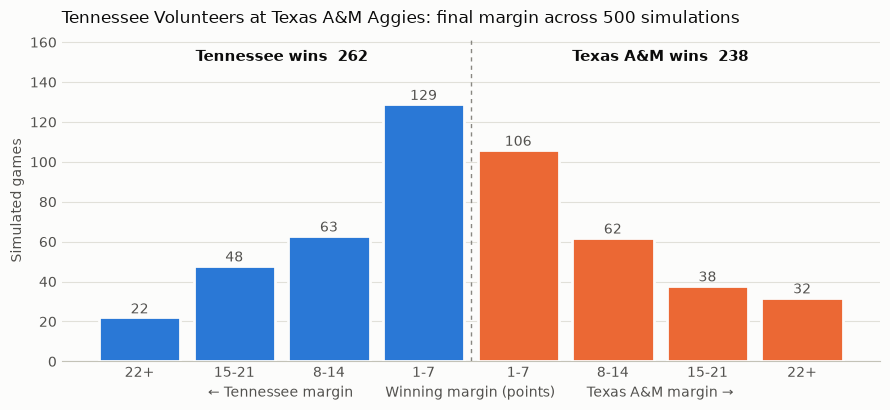

In [12]:
# Distribution of the final margin. There are no ties: overtime decides every game.
edges = [-100, -22, -15, -8, 0, 7, 14, 21, 100]   # bins are (left, right], so -8 to 0 means a 1-7 point away win
buckets = ["22+", "15-21", "8-14", "1-7", "1-7", "8-14", "15-21", "22+"]
labels = [f"b{i}" for i in range(len(buckets))]
dist = pd.cut(RESULTS.margin_home, edges, labels=labels).value_counts().reindex(labels).fillna(0).astype(int)

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
AWAY_COLOR, HOME_COLOR = "#2a78d6", "#eb6834"   # categorical slots 1 and 2 (validated colorblind-safe pair)
colors = [AWAY_COLOR] * 4 + [HOME_COLOR] * 4

fig, ax = plt.subplots(figsize=(9, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
x = np.arange(len(dist))
bars = ax.bar(x, dist.values, width=0.86, color=colors, edgecolor=SURFACE, linewidth=2, zorder=3)
for xi, v in zip(x, dist.values):
    ax.text(xi, v + 0.4, str(v), ha="center", va="bottom", fontsize=10, color=INK_2)

ax.axvline(3.5, color=MUTED, linewidth=1, linestyle=(0, (3, 3)), zorder=2)
ymax = max(dist.max(), 1) * 1.25
ax.set_ylim(0, ymax)
ax.text(1.5, ymax * 0.97, f"{A.short} wins  {(RESULTS.margin_home < 0).sum()}", ha="center", va="top",
        fontsize=11, fontweight="bold", color=INK)
ax.text(5.5, ymax * 0.97, f"{H.short} wins  {(RESULTS.margin_home > 0).sum()}", ha="center", va="top",
        fontsize=11, fontweight="bold", color=INK)

ax.set_xticks(x, buckets)
ax.set_xlabel(f"← {A.short} margin        Winning margin (points)        {H.short} margin →", color=INK_2, fontsize=10)
ax.set_ylabel("Simulated games", color=INK_2, fontsize=10)
ax.set_title(f"{A.name} at {H.name}: final margin across {len(RESULTS)} simulations",
             loc="left", fontsize=12, color=INK, pad=12)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(colors=MUTED, labelcolor=INK_2, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
plt.tight_layout()
plt.show()

In [13]:
print("Most common final scores:")
print((RESULTS[A.name].astype(str) + "-" + RESULTS[H.name].astype(str)).value_counts().head(10).to_string())
RESULTS.head(20)

Most common final scores:
24-17    7
27-24    6
24-27    6
21-26    5
10-17    5
24-21    5
26-21    5
14-21    5
20-24    4
14-20    4


,Tennessee Volunteers,Texas A&M Aggies,winner,margin_home,ot,Tennessee yds,Texas A&M yds
sim,,,,,,,
1,34,28,Tennessee,-6,False,381,550
2,22,20,Tennessee,-2,False,458,343
3,20,24,Texas A&M,4,True,320,332
4,27,13,Tennessee,-14,False,338,254
5,24,13,Tennessee,-11,False,427,321
6,34,35,Texas A&M,1,False,401,391
7,26,28,Texas A&M,2,False,438,256
8,10,13,Texas A&M,3,False,384,222
9,13,29,Texas A&M,16,False,136,458


## 11. Average team and player stats across all simulations

In [14]:
avg_team = pd.DataFrame({
    r.name: {"points": np.mean([g.score[tid] for g in GAMES]),
             **{k: np.mean([g.team[tid][k] for g in GAMES]) for k in
                ["first_downs", "plays", "yards", "pass_yds", "rush_yds", "completions", "pass_att", "rush_att",
                 "turnovers", "sacks_allowed", "penalties", "pen_yds"]},
             "time_of_poss_min": np.mean([g.team[tid]["top"] for g in GAMES]) / 60}
    for tid, r in ((AWAY_ID, A), (HOME_ID, H))})
avg_team.round(1)

,Tennessee Volunteers,Texas A&M Aggies
points,22.8,22.7
first_downs,15.0,17.2
plays,63.5,66.9
yards,359.4,356.9
pass_yds,195.6,190.6
rush_yds,174.2,181.6
completions,16.3,17.9
pass_att,27.7,30.4
rush_att,33.8,33.6
turnovers,0.9,1.2


In [15]:
for tid, r in ((AWAY_ID, A), (HOME_ID, H)):
    show_player_tables(player_tables(average_players(GAMES, tid)), f"{r.name}: average per game over {len(GAMES)} sims",
                       decimals=1)


=== Tennessee Volunteers: average per game over 500 sims ===

PASSING
                  comp   att  pass_yds  pass_td  int  sacked
George MacIntyre  15.3  26.1     184.4      1.2  0.6     1.8
Faizon Brandon     0.9   1.6      11.2      0.1  0.0     0.1

RUSHING
                  carries  rush_yds  ypc  rush_td  rush_long
DeSean Bishop        21.2     107.1  5.0      0.9       26.8
Daune Morris          5.5      29.1  5.3      0.2       14.5
George MacIntyre      3.2      16.3  5.1      0.1       10.8
Javin Gordon          2.2      12.7  5.8      0.1        9.7
Hunter Barnes         0.5       2.3  4.8      0.0        5.9
Mike Matthews         0.4       2.1  4.8      0.0        6.2
Braylon Staley        0.2       1.3  5.5      0.0        6.0
DaSaahn Brame         0.2       1.2  5.3      0.0        6.0

RECEIVING
                   targets  rec  rec_yds  rec_td  rec_long
Mike Matthews          8.1  4.5     61.3     0.4      27.5
Braylon Staley         8.0  4.8     52.6     0.3      25.3


## 12. One full simulated game
The simulation closest to the median result, with its box score, scoring summary and the full
play-by-play log.

In [16]:
target = RESULTS.margin_home.median()
pick_sim = (RESULTS.margin_home - target).abs().idxmin()
G = GAMES[pick_sim - 1]
line = pd.DataFrame({r.name: G.qscore[tid] + [G.score[tid]] for tid, r in ((AWAY_ID, A), (HOME_ID, H))},
                    index=["Q1", "Q2", "Q3", "Q4/OT", "Final"]).T
print(f"Simulation #{pick_sim}")
print(line.to_string())
print()
print(team_box(G).to_string())

Simulation #2
                      Q1  Q2  Q3  Q4/OT  Final
Tennessee Volunteers   7   3   9      3     22
Texas A&M Aggies       7   7   6      0     20

              Texas A&M Aggies Tennessee Volunteers
points                      20                   22
first_downs                 19                   17
plays                       76                   62
yards                      343                  458
pass_yds                   223                  255
rush_yds                   146                  206
comp_att                 22/37                19/30
rush_att                    35                   31
third_down                6/14                 5/14
turnovers                    0                    0
sacks_allowed                4                    1
penalties                 2-15                 6-45
top                      32:00                28:00


In [17]:
pd.DataFrame(G.scoring)

,when,team,play,Tennessee,Texas A&M
0,Q1 6:21,Texas A&M,Jamarion Morrow 2 yd run,0,7
1,Q1 1:03,Tennessee,DeSean Bishop 7 yd run,7,7
2,Q2 9:57,Tennessee,Cooper Ranvier 21 yd FG,10,7
3,Q2 0:34,Texas A&M,Marcel Reed 5 yd pass to Houston Thomas,10,14
4,Q3 11:07,Texas A&M,Marcel Reed 5 yd pass to Aaron Gregory,10,20
5,Q3 6:53,Tennessee,safety,12,20
6,Q3 3:22,Tennessee,Mike Matthews 63 yd run,19,20
7,Q4 13:18,Tennessee,Cooper Ranvier 44 yd FG,22,20


In [18]:
for tid, r in ((AWAY_ID, A), (HOME_ID, H)):
    show_player_tables(player_tables(G.player[tid]), f"{r.name} box score (sim #{pick_sim})", top=10)


=== Tennessee Volunteers box score (sim #2) ===

PASSING
                  comp   att  pass_yds  pass_td  int  sacked
George MacIntyre  19.0  30.0     255.0      0.0  0.0     1.0

RUSHING
                  carries  rush_yds   ypc  rush_td  rush_long
DeSean Bishop        19.0      78.0   4.0      1.0       19.0
Daune Morris          4.0      30.0   8.0      0.0       21.0
George MacIntyre      3.0       8.0   3.0      0.0        4.0
Mike Matthews         2.0      68.0  34.0      1.0       63.0
Javin Gordon          2.0       9.0   4.0      0.0        7.0
DaSaahn Brame         1.0      13.0  13.0      0.0       13.0

RECEIVING
                   targets  rec  rec_yds  rec_td  rec_long
Mike Matthews         13.0  9.0    170.0     0.0      68.0
DeSean Bishop          2.0  2.0     37.0     0.0      34.0
Braylon Staley         8.0  4.0     15.0     0.0       6.0
DaSaahn Brame          2.0  2.0     14.0     0.0      10.0
Trent Thomas           1.0  1.0     10.0     0.0      10.0
TK Keys     

In [19]:
print("\n".join(G.pbp))

 Q1 15:00  Tennessee    kickoff, drive starts at own 23
 Q1 14:54  Tennessee    Daune Morris rush for 21
 Q1 14:23  Tennessee    George MacIntyre pass complete to DeSean Bishop for 3
 Q1 13:54  Tennessee    DeSean Bishop rush for 1
 Q1 13:23  Tennessee    DeSean Bishop rush for 1
 Q1 12:52  Tennessee    Jackson Ross punts, net 39
 Q1 12:44  Texas A&M    KJ Edwards rush for 4
 Q1 12:11  Texas A&M    Marcel Reed pass complete to Houston Thomas for 15
 Q1 11:41  Texas A&M    Marcel Reed pass incomplete to Isaiah Horton
 Q1 11:36  Texas A&M    Rueben Owens II rush for 3
 Q1 11:03  Texas A&M    Marcel Reed pass incomplete to Isaiah Horton
 Q1 10:58  Texas A&M    Tyler White punts, net 48
 Q1 10:50  Tennessee    DeSean Bishop rush for 19
 Q1 10:19  Tennessee    George MacIntyre sacked by Marco Jones for -3
  Q1 9:46  Tennessee    George MacIntyre rush for 2
  Q1 9:15  Tennessee    George MacIntyre pass complete to Braylon Staley for -1
  Q1 8:46  Tennessee    Jackson Ross punts, net 1
  Q1 8